[Sommaire](00_sommaire.ipynb) · ⬅ [Thème 3 — Fenêtre glissante](theme3_fenetre_deux_pointeurs.ipynb) · [Thème 5 — BFS / DFS](theme5_bfs_dfs.ipynb) ➡

# Thème 4 — La pile (stack)

**Dans ce notebook, tu vas apprendre :**
- ce qu'est une pile (« dernier arrivé, premier sorti ») et comment l'utiliser en Python ;
- pourquoi la pile est l'outil naturel pour les parenthèses ;
- reconnaître les autres problèmes où une pile s'impose.

**Prérequis :** thèmes 0 et 1 (notation O, dict)

> Exécute d'abord la cellule ci-dessous : elle contient l'outil `verifier`, qui teste automatiquement ta solution dans l'exercice final.

In [ ]:
# Outil utilisé dans l'exercice « À toi de jouer » de ce notebook.
# Il appelle ta fonction sur plusieurs cas et affiche ✅ (bon), ❌ (mauvais) ou 💥 (plantage).
# Tu n'as pas besoin de comprendre ce code pour t'en servir : exécute simplement cette cellule.

import copy

def verifier(fonction, cas):
    reussis = 0
    for arguments, attendu in cas:
        texte_args = ", ".join(repr(a) for a in arguments)
        try:
            obtenu = fonction(*copy.deepcopy(arguments))
        except Exception as erreur:
            print(f"💥 {fonction.__name__}({texte_args}) a planté : {type(erreur).__name__}: {erreur}")
            continue
        if obtenu == attendu:
            reussis += 1
            print(f"✅ {fonction.__name__}({texte_args}) -> {obtenu!r}")
        else:
            print(f"❌ {fonction.__name__}({texte_args}) -> {obtenu!r}   (attendu : {attendu!r})")
    print(f"\n{reussis}/{len(cas)} tests réussis")

## Le problème de départ
> Une chaîne contient des `()`, `[]` et `{}`. Est-elle **bien parenthésée** ? Chaque ouvrante doit être fermée par la bonne fermante, dans le bon ordre.
> `"{[()()]}"` → valide · `"([)]"` → invalide · `"((("` → invalide

## Le concept : une pile d'assiettes
Une **pile** est une structure où l'on ne touche **qu'au sommet** :
- on **empile** : on pose un élément sur le dessus ;
- on **dépile** : on retire l'élément du dessus ;
- on peut **regarder** le sommet sans le retirer.

Règle fondamentale : **le dernier arrivé est le premier sorti** (en anglais *LIFO : Last In, First Out*). Comme une pile d'assiettes : on ne retire pas celle du milieu.

En Python, une simple liste fait l'affaire, en considérant que **le sommet est la fin de la liste** :

| Opération | Code Python | Coût |
|---|---|---|
| empiler `x` | `pile.append(x)` | O(1) |
| dépiler | `pile.pop()` (renvoie l'élément retiré) | O(1) |
| regarder le sommet | `pile[-1]` | O(1) |
| la pile est-elle vide ? | `not pile` (vrai si vide) | O(1) |

## On manipule

In [ ]:
pile = []
pile.append("(")      # pile : ['(']
pile.append("[")      # pile : ['(', '[']
pile.append("{")      # pile : ['(', '[', '{']   ← '{' est au sommet
print("sommet :", pile[-1])

retire = pile.pop()   # retire le DERNIER ajouté
print("retiré :", retire, "| pile :", pile)

print("vide ?", not pile)
pile.pop()
pile.pop()
print("vide ?", not pile)

try:
    pile.pop()        # dépiler une pile vide…
except IndexError as e:
    print("IndexError :", e, "→ toujours vérifier que la pile n'est pas vide avant pop() ou pile[-1]")

## Pourquoi une pile colle parfaitement aux parenthèses
Quand on a lu `( [ {`, la prochaine fermante doit correspondre à **la dernière ouverture pas encore fermée** : `{`. Ensuite à `[`, puis à `(`. On ferme dans **l'ordre inverse** de l'ouverture : c'est exactement « dernier arrivé, premier sorti ».

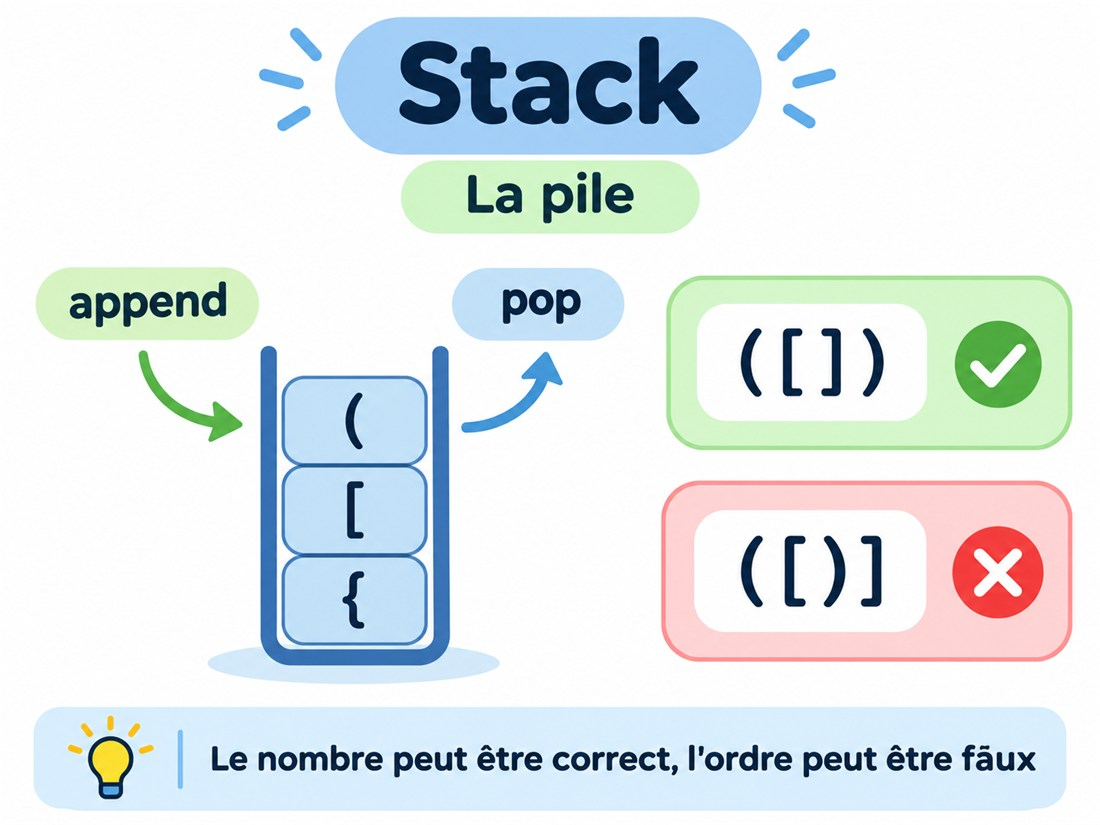

Sur l'image, on a empilé `{`, puis `[`, puis `(` avec `append` : c'est `(`, **la dernière arrivée**, qui est au sommet, et c'est elle que `pop` retirera en premier. La prochaine fermante doit donc être `)`. À droite, `([])` est valide mais `([)]` ne l'est pas, alors qu'il contient le même nombre de chaque symbole : c'est l'objet de la section suivante.

### Pourquoi compter ne suffit pas
`"([)]"` contient une `(` et une `)`, un `[` et un `]` : les **nombres** sont corrects. Mais au moment où on lit `)`, la dernière ouverture non fermée est `[` → mauvaise fermeture. Un compteur ne sait rien de l'**ordre** ; la pile, si.

## L'algorithme en mots
Pour chaque caractère :
- si c'est une **ouvrante** → on l'empile ;
- si c'est une **fermante** → le sommet doit être l'ouvrante correspondante : si oui, on dépile ; sinon, c'est invalide.

À la fin, la pile doit être **vide** : toute ouverture a été fermée.

Il y a donc **trois façons d'échouer** :
| Cas | Exemple | Ce qui se passe |
|---|---|---|
| mauvaise fermante | `"([)]"` | on lit `)` mais le sommet est `[` |
| fermante en trop | `"())"` | on lit `)` alors que la pile est **vide** |
| ouvrante jamais fermée | `"((("` | fin du texte et la pile n'est **pas vide** |

**Trace à la main sur `"{[()()]}"` :**

| Lu | Action | Pile après |
|---|---|---|
| `{` | empiler | `{` |
| `[` | empiler | `{ [` |
| `(` | empiler | `{ [ (` |
| `)` | sommet `(` ✓ → dépiler | `{ [` |
| `(` | empiler | `{ [ (` |
| `)` | sommet `(` ✓ → dépiler | `{ [` |
| `]` | sommet `[` ✓ → dépiler | `{` |
| `}` | sommet `{` ✓ → dépiler | *(vide)* |

Fin du texte, pile vide → **valide**.

**Trace à la main sur `"([)]"` :**

| Lu | Action | Pile après |
|---|---|---|
| `(` | empiler | `(` |
| `[` | empiler | `( [` |
| `)` | sommet `[`, or il faudrait `(` ✗ | → **invalide** |

Pour voir la pile évoluer sur n'importe quelle chaîne :

In [ ]:
def voir_pile(texte):
    correspondance = {')': '(', ']': '[', '}': '{'}
    pile = []
    for c in texte:
        if c in "([{":
            pile.append(c)
            print(f"lu {c} → {'empiler':<18} pile = {' '.join(pile)}")
        elif c in ")]}":
            if not pile:
                print(f"lu {c} → pile vide : fermante en trop → INVALIDE")
                return
            if pile[-1] != correspondance[c]:
                print(f"lu {c} → le sommet est {pile[-1]}, il faudrait {correspondance[c]} → INVALIDE")
                return
            pile.pop()
            action = f"ferme {correspondance[c]}, dépiler"
            print(f"lu {c} → {action:<18} pile = {' '.join(pile)}")
    if pile:
        print(f"fin : il reste {' '.join(pile)} non fermé(s) → INVALIDE")
    else:
        print("fin : pile vide → VALIDE")

voir_pile("{[()()]}")
print()
voir_pile("([)]")

### Le code de la solution

In [ ]:
def parentheses_valides(texte):
    # Pour chaque fermante : l'ouvrante qui doit se trouver au sommet de la pile
    correspondance = {')': '(', ']': '[', '}': '{'}
    pile = []

    for c in texte:
        if c in "([{":                      # ouvrante → on la retient
            pile.append(c)
        elif c in ")]}":                    # fermante → elle doit fermer la DERNIÈRE ouverture
            if not pile or pile[-1] != correspondance[c]:
                return False                # fermante en trop, ou mauvaise paire
            pile.pop()                      # bonne paire : cette ouverture est fermée
        # les autres caractères (lettres, chiffres…) sont ignorés

    return len(pile) == 0                   # aucune ouverture ne doit rester ouverte

tests = ["([])", "([)]", "(((", "())", "{[()()]}", "", "a(b)c"]
for t in tests:
    print(repr(t), "->", parentheses_valides(t))

**Détail important : l'ordre dans `if not pile or pile[-1] != correspondance[c]`.**
Python évalue un `or` de gauche à droite et **s'arrête dès qu'une partie est vraie**. Si la pile est vide, `not pile` est vrai : Python n'évalue jamais `pile[-1]`, qui aurait planté. Si on inverse les deux conditions, `"())"` provoque une `IndexError`.

## La pile ailleurs que dans les parenthèses
Dès qu'un élément doit être « fermé » ou « annulé » par **le plus récent**, pense à une pile :
- le bouton **Annuler** (Ctrl+Z) annule la dernière action ;
- le bouton **Retour** du navigateur revient à la page précédente ;
- les balises HTML imbriquées `<div><p></p></div>` ;
- des éléments qui **s'annulent par paires** au fil de la lecture (exercice ci-dessous).

## Quand y penser ?
- parenthèses, crochets, balises, « bien imbriqué », « bien formé » ;
- « annuler », « revenir en arrière », « le plus récent » ;
- des éléments qui s'annulent par paires au fur et à mesure qu'on lit.

## Les pièges
- `pile[-1]` ou `pile.pop()` sur une pile vide → `IndexError` : tester `not pile` **avant**.
- Oublier la vérification finale `len(pile) == 0` (sinon `"((("` serait déclaré valide).
- Croire qu'un compteur suffit (c'est vrai seulement s'il n'y a **qu'un seul type** de parenthèse).

## À toi de jouer — supprimer les paires adjacentes
> On supprime, tant que c'est possible, deux lettres **identiques et côte à côte**. Renvoie la chaîne finale.
> `"abbaca"` → on supprime `bb` → `"aaca"` → on supprime `aa` → `"ca"`.

**Indice** : lis les lettres une par une en les empilant. Si la lettre lue est **égale au sommet**, les deux s'annulent : dépile au lieu d'empiler. À la fin, `"".join(pile)` reconstruit la chaîne.

In [ ]:
def supprimer_paires(texte):
    # À toi de jouer !
    pass

verifier(supprimer_paires, [
    (("abbaca",), "ca"),
    (("azxxzy",), "ay"),
    (("aa",), ""),
    (("abc",), "abc"),
    (("",), ""),
])

<details>
<summary><b>Voir la solution</b> (essaie vraiment d'abord !)</summary>

```python
def supprimer_paires(texte):
    pile = []
    for c in texte:
        if pile and pile[-1] == c:   # même lettre que le sommet → elles s'annulent
            pile.pop()
        else:
            pile.append(c)
    return "".join(pile)
```

</details>

---

**Suite :** [Thème 5 — Explorer une grille ou un graphe : BFS et DFS](theme5_bfs_dfs.ipynb) ➡ · [Retour au sommaire](00_sommaire.ipynb)

**S'entraîner :** [Série 4 — Piles et files](exercices/serie4_piles_files.ipynb) (5 exercices avec tests automatiques), à faire après le thème 5 : l'un d'eux utilise la file (`deque`), présentée au thème 5